I decided to split the analysis into more files since I don't need to run the PINN everytime I do a Bayesian

In [21]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
import os

# the same PINN as it was in magnetic PINN analysis

class PINN(nn.Module):
  def __init__(self):
    super(PINN, self).__init__()
    self.net = nn.Sequential(
      nn.Linear(3, 64),
      nn.SiLU(),
      nn.Linear(64, 128),
      nn.SiLU(),
      nn.Linear(128, 128),
      nn.SiLU(),
      nn.Linear(128, 128),
      nn.SiLU(),
      nn.Linear(128, 128),
      nn.SiLU(),
      nn.Linear(128, 64),
      nn.Tanh(),
      nn.Linear(64, 3)
    )

  def forward(self, x):
    return self.net(x)


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
orbits = ["ORB04", 'ORB12', 'ORB14', 'ORB19', 'ORB26']
folder_name = '_regular'


for orbit in orbits:
  input_name = f"{orbit}_EUR_EPHIO.csv"
  model_path = f"{folder_name}/europa_pinn_model_{orbit}.pth"


  if not os.path.exists(input_name) or not os.path.exists(model_path):
    print(f"One of the paths does not exist for orbit {orbit}. Skipping this one")
    continue

  # get values from the NASA .csv file
  df = pd.read_csv(input_name)

  X_raw = df[['X', 'Y', 'Z']].values
  y_raw = df[['BX', 'BY', 'BZ']].values

  input_scaler = MinMaxScaler(feature_range=(-1, 1))
  output_scaler = MinMaxScaler(feature_range=(-1, 1))

  X_scaled = input_scaler.fit_transform(X_raw)
  output_scaler.fit(y_raw)

  # evaluation using models saved .pth files (weights from PINN)
  model = PINN().to(device)
  model.load_state_dict(torch.load(model_path, map_location=device))
  model.eval()

  with torch.no_grad():
    X_tensor = torch.tensor(X_scaled, dtype=torch.float32).to(device)
    pred_scaled = model(X_tensor)
    # unscale it back from (-1,1_ to nanoTesla values
    pred_raw = output_scaler.inverse_transform(pred_scaled.cpu().numpy())


  df['BX_PINN'] = pred_raw[:,0]
  df['BY_PINN'] = pred_raw[:,1]
  df['BZ_PINN'] = pred_raw[:,2]

  out_filename = f"{orbit}_PINN_filtered.csv"
  df.to_csv(out_filename, index=False)
  print(f"Orbit {orbit} save to {out_filename}.")


Orbit ORB04 save to ORB04_PINN_filtered.csv.
Orbit ORB12 save to ORB12_PINN_filtered.csv.
Orbit ORB14 save to ORB14_PINN_filtered.csv.
Orbit ORB19 save to ORB19_PINN_filtered.csv.
Orbit ORB26 save to ORB26_PINN_filtered.csv.


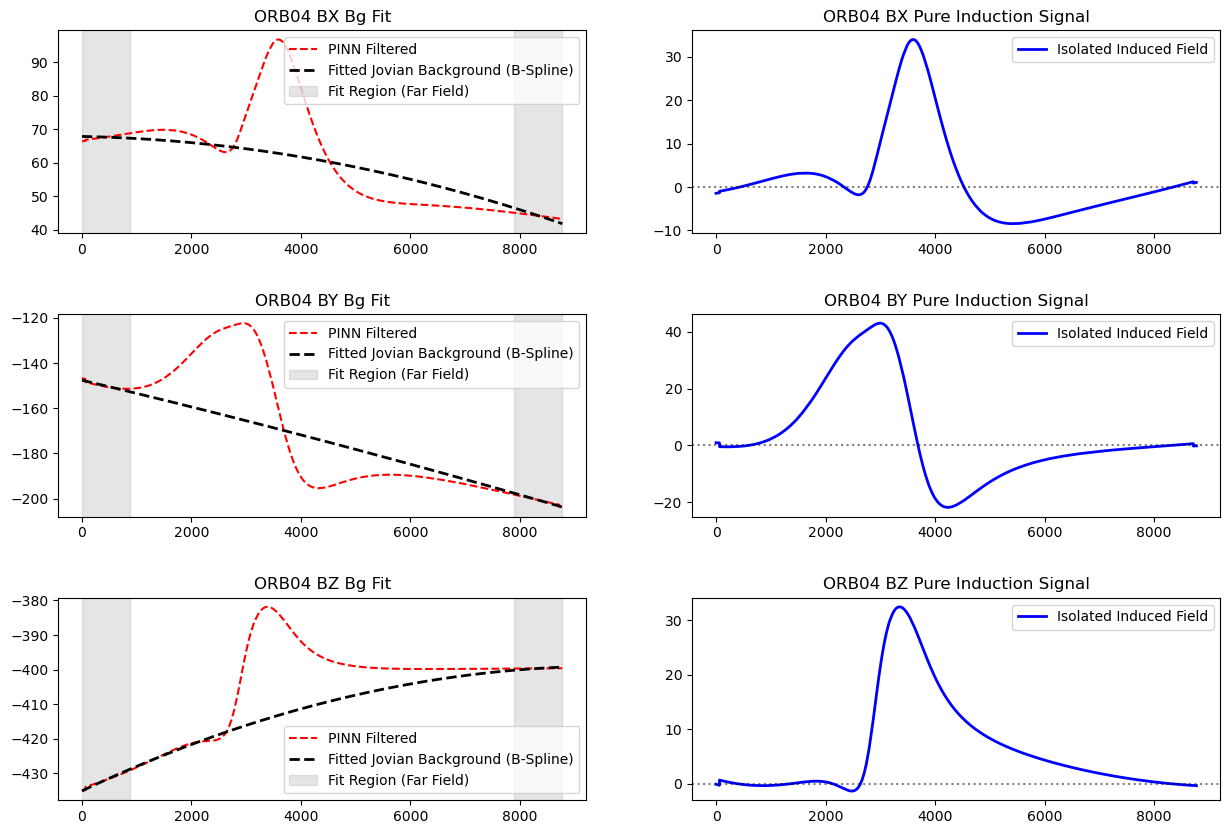

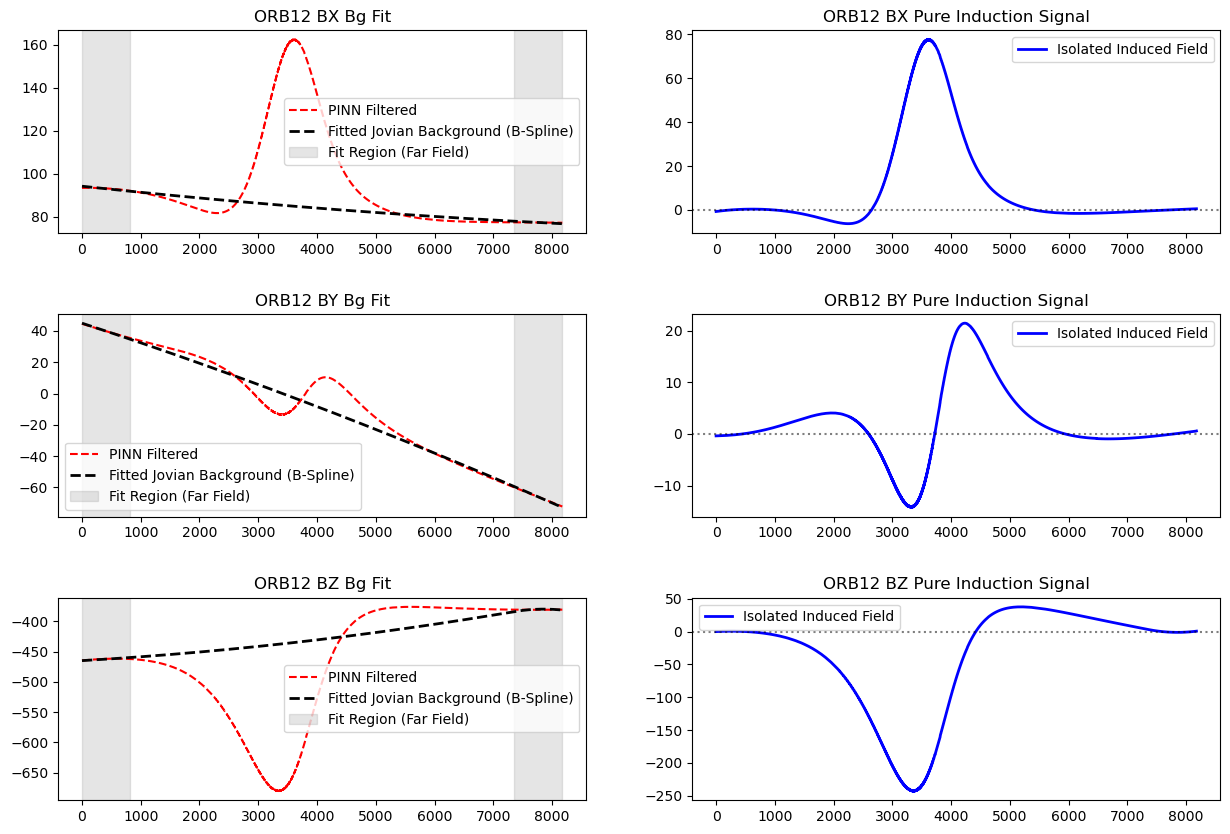

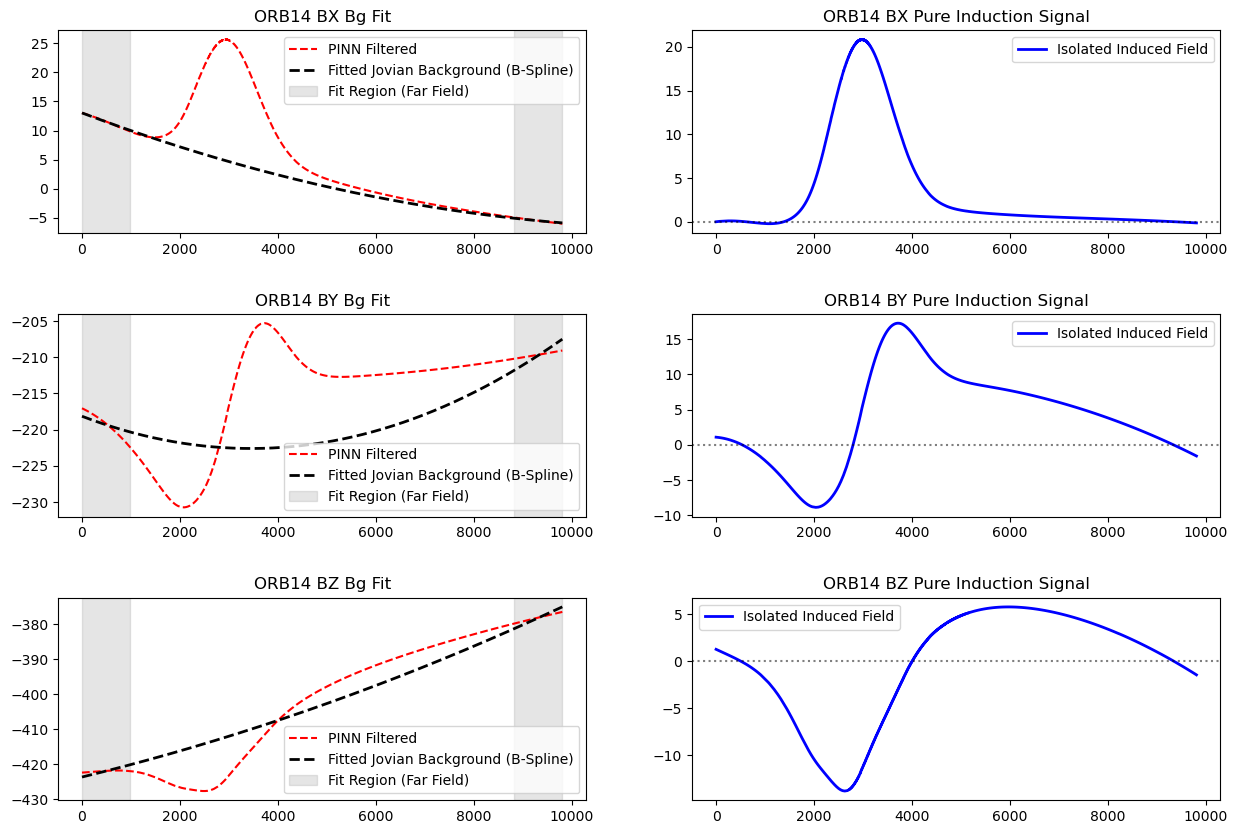

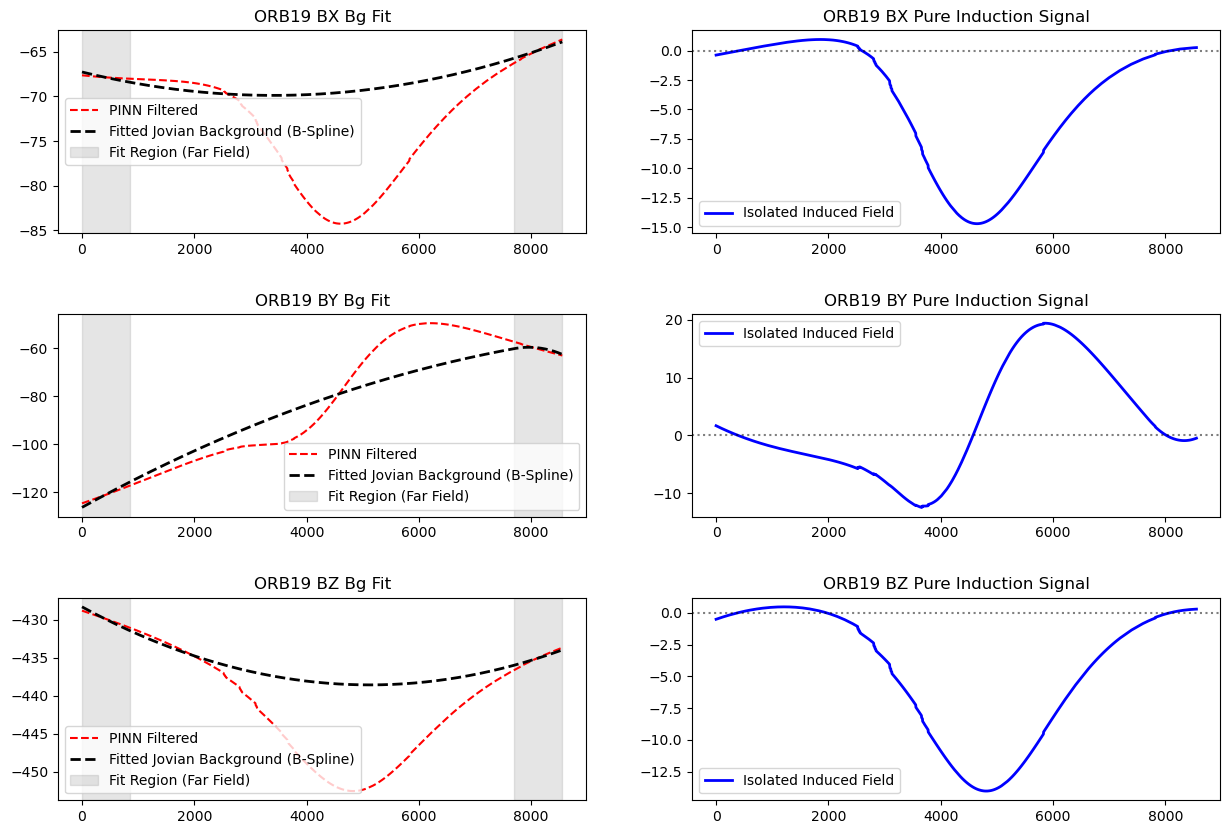

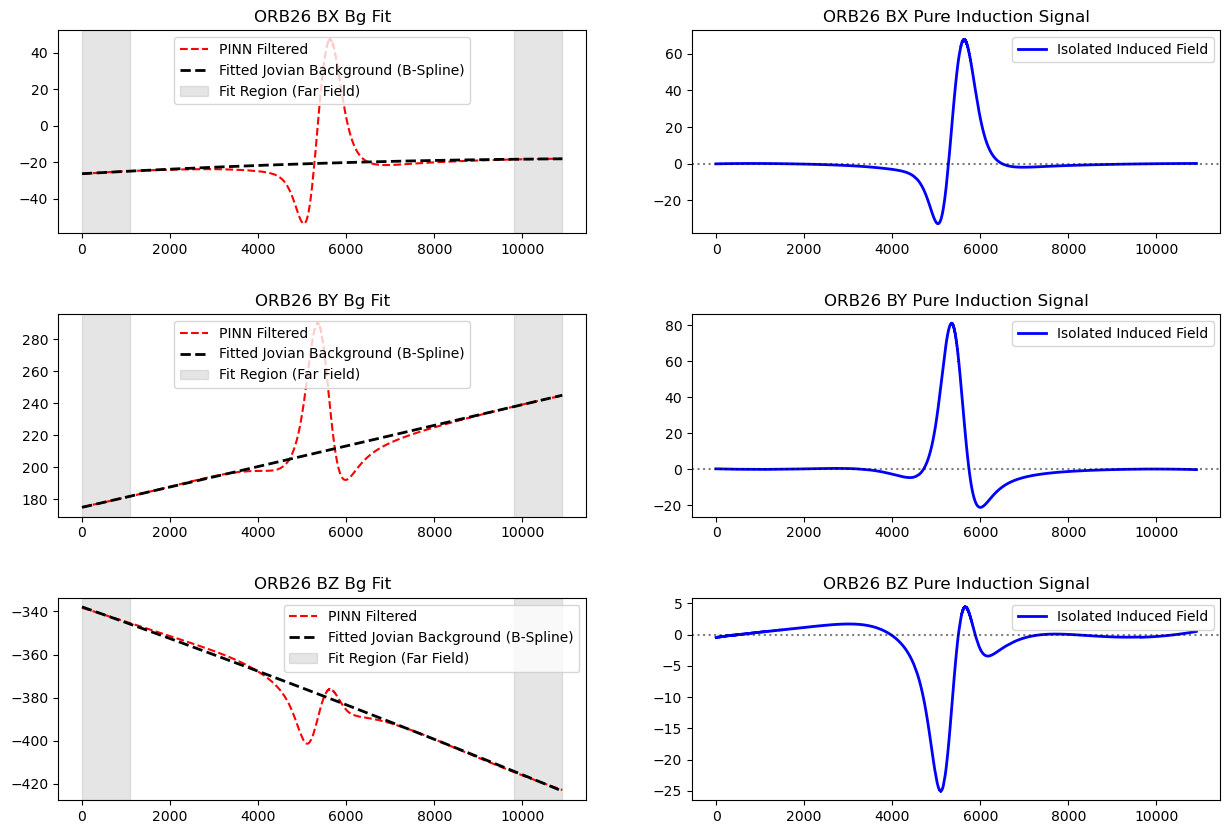


--- ORB04 ---
BX Shape: 8775
BX Array: [67.87530793 67.87498538 67.87466221 ... 41.82494939 41.81933191
 41.81371383]
BY Shape: 8775
BY Array: [-147.57911074 -147.58488002 -147.59064945 ... -203.7009212  -203.70794773
 -203.7149744 ]
BZ Shape: 8775
BZ Array: [-435.10702091 -435.09954567 -435.0920712  ... -399.302176   -399.30148857
 -399.30080192]

--- ORB12 ---
BX Shape: 8176
BX Array: [94.11050705 94.10756846 94.10463006 ... 76.64874574 76.6474115
 76.64607745]
BY Shape: 8176
BY Array: [ 44.93042682  44.91814176  44.90585619 ... -72.71312648 -72.72963028
 -72.7461346 ]
BZ Shape: 8176
BZ Array: [-464.88921764 -464.883557   -464.8778949  ... -381.28830558 -381.29852388
 -381.30877484]

--- ORB14 ---
BX Shape: 9805
BX Array: [13.02681522 13.02364912 13.02048328 ... -5.84943389 -5.85011905
 -5.85080395]
BY Shape: 9805
BY Array: [-218.15839044 -218.16096961 -218.16354803 ... -207.52343097 -207.51868109
 -207.51393047]
BZ Shape: 9805
BZ Array: [-423.66161666 -423.65819858 -423.65478018 ..

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import splrep, splev

# extracting the background magnetic field
primary_fields = {
  # orbit : [Bx, By, Bz]
  'ORB04' : [0, 0, 0],
  'ORB12' : [0, 0, 0],
  'ORB14' : [0, 0, 0],
  'ORB19' : [0, 0, 0],
  'ORB26' : [0, 0, 0]
}

# Assumes 'orbits' list is defined previously
for orbit in orbits:
  df = pd.read_csv(f"{orbit}_PINN_filtered.csv")

  t = np.arange(len(df))

  # percent of edge margin
  edge_margin = int(len(df) * 0.10)

  # boolean mask of ones only at the 10% of the edges
  edge_mask = np.ones(len(df), dtype=bool)
  edge_mask[edge_margin:-edge_margin] = False

  components = ['BX', 'BY', 'BZ']
  spline_degrees = [2, 2, 2] # quadratic fit (k=2)

  fig, axes = plt.subplots(3, 2, figsize=(15, 10))
  plt.subplots_adjust(hspace=0.4)

  for i, comp in enumerate(components):
    pinn_col = f"{comp}_PINN"
    B_pinn = df[pinn_col].values

    # use masks to get edges
    t_edges = t[edge_mask]
    B_edges = B_pinn[edge_mask]

    # k - degree
    # s - smoothing factor
    tck = splrep(t_edges, B_edges, k=spline_degrees[i], s=len(t_edges))

    # eval across entire flyby
    B_primary = splev(t, tck)
    primary_fields[orbit][i] = B_primary

    # isolate Europa's induced field
    B_induced = B_pinn - B_primary
    df[f"{comp}_INDUCED"] = B_induced

    # plot
    # left column: PINN data vs B-Spline bg.
    axes[i, 0].plot(t, B_pinn, 'r--', label="PINN Filtered")
    axes[i, 0].plot(t, B_primary, 'k--', linewidth=2, label="Fitted Jovian Background (B-Spline)")
    axes[i, 0].axvspan(0, edge_margin, color='gray', alpha=0.2, label="Fit Region (Far Field)")
    axes[i, 0].axvspan(len(df) - edge_margin, len(df), color='gray', alpha=0.2)
    axes[i, 0].set_title(f"{orbit} {comp} Bg Fit")
    axes[i, 0].legend(loc='best')

    # right column: the isolated induced field
    axes[i, 1].plot(t, B_induced, 'b-', linewidth=2, label='Isolated Induced Field')
    axes[i, 1].axhline(0, color='k', linestyle=":", alpha=0.5)
    axes[i, 1].set_title(f"{orbit} {comp} Pure Induction Signal")
    axes[i, 1].legend(loc='best')

  plt.savefig(f"{orbit}_BSpline_Extraction.png", bbox_inches='tight')
  plt.show()

  # save updated df for 3d mcmc inversion
  df.to_csv(f"{orbit}_INDUCTION_READY.csv", index=False)

# for orbit in primary_fields:
#   print(f"\n{orbit}")
#   for i, comp in enumerate(['BX', 'BY', 'BZ']):
#       print(f"{comp} Shape: {len(primary_fields[orbit][i])}")
#       print(f"{comp} Array: {primary_fields[orbit][i]}")

In [24]:
# MCMC inversion
import emcee
import corner

df = pd.read_csv(f"{orbit}_INDUCTION_READY.csv")

# extract Galileo spacecraft coordinates
X = df['X'].values
Y = df['Y'].values
Z = df['Z'].values

# standarize
if np.max(np.abs(X)) > 100:
  X = X / 1560.8
  Y = Y / 1560.8
  Z = Z / 1560.8

# extract the pure induced field
BX_ind = df['BX_INDUCED'].values
BY_ind = df['BY_INDUCED'].values
BZ_ind = df['BZ_INDUCED'].values

# calc Jupiter's primary field magnitude (Actual B - Induced B)
BX_pri = df["BX"].values - BX_ind
BY_pri = df['BY'].values - BY_ind
BZ_pri = df['BZ'].values - BZ_ind

B_pri_mag = np.sqrt(BX_pri**2 + BY_pri**2 + BZ_pri**2)
mean_B_pri = np.mean(B_pri_mag)

# 3D spatial dipole forward model
def dipole_field(mx, my, mz, x, y, z):
  r2 = x**2 + y**2 + z**2
  r5 = r2**(2.5)
  dot_product = mx*x + my*y + mz*z

  bx = (3 * dot_product * x - mx * r2) / r5
  by = (3 * dot_product * y - my * r2) / r5
  bz = (3 * dot_product * z - mz * r2) / r5

  return bx, by, bz

def log_prior(theta):
  mx, my, mz = theta
  # boundaries for Europa's induced dipole moment
  if -500 < mx < 500 and -500 < my < 500 and -500 < mz < 500:
    return 0
  return -np.inf

def log_likelihood(theta, x, y, z, bx_obs, by_obs, bz_obs):
  mx, my, mz = theta
  bx_mod, by_mod, bz_mod = dipole_field(mx, my, mz, x, y, z)

  sigma2 = 2.0**2 # Assume 2nT instrument/model uncertainty

  ll_x = -0.5 * np.sum((bx_obs - bx_mod)**2 / sigma2)
  ll_y = -0.5 * np.sum((by_obs - by_mod)**2 / sigma2)
  ll_z = -0.5 * np.sum((bz_obs - bz_mod)**2 / sigma2)

  return ll_x + ll_y + ll_z

def log_probability(theta, x, y, z, bx_obs, by_obs, bz_obs):
  lp = log_prior(theta)
  if not np.isfinite(lp):
    return -np.inf
  return lp + log_likelihood(theta, x, y, z, bx_obs, by_obs, bz_obs)



MCMC for ORB04


100%|██████████| 4000/4000 [00:26<00:00, 148.65it/s]


samples shape, for orbit: ORB04 : 96000
samples shapes x, y, z: 96000, 96000, 96000


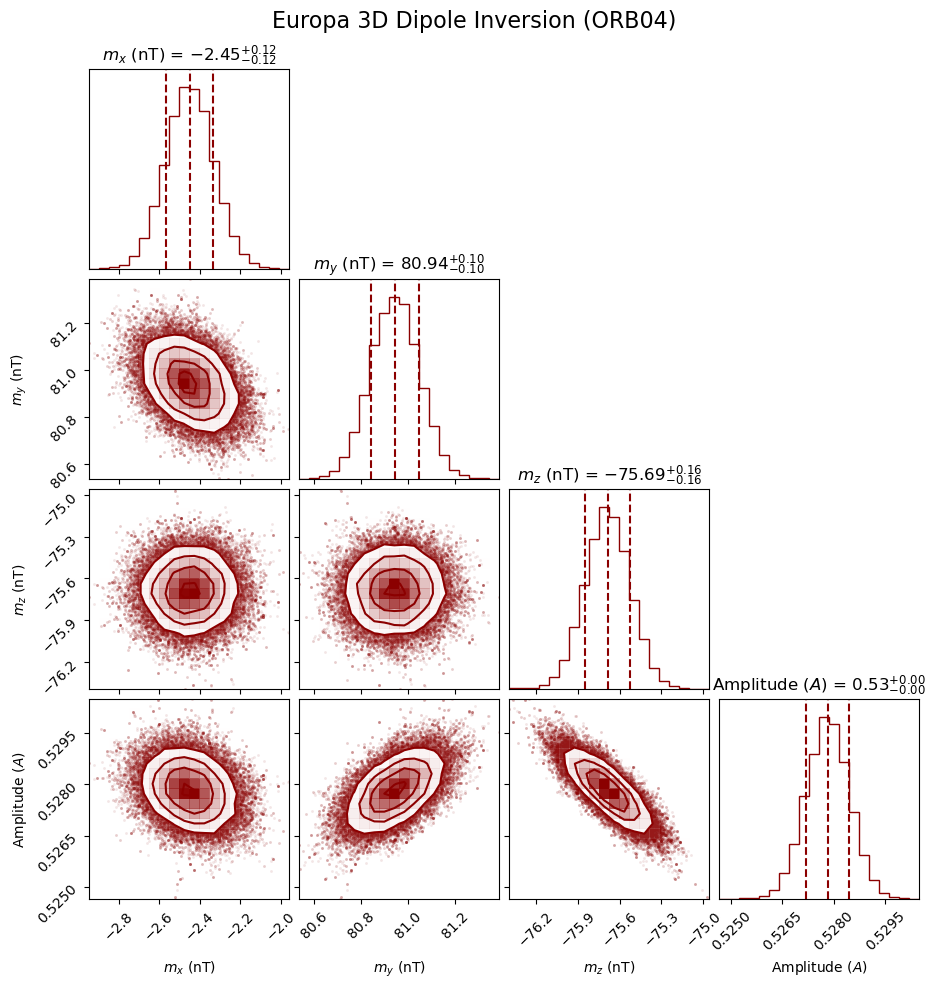

Amplitude (A) : 0.528
Phase Lag (phi) : 19.34 degrees

MCMC for ORB12


100%|██████████| 4000/4000 [00:26<00:00, 150.55it/s]


samples shape, for orbit: ORB12 : 96000
samples shapes x, y, z: 96000, 96000, 96000


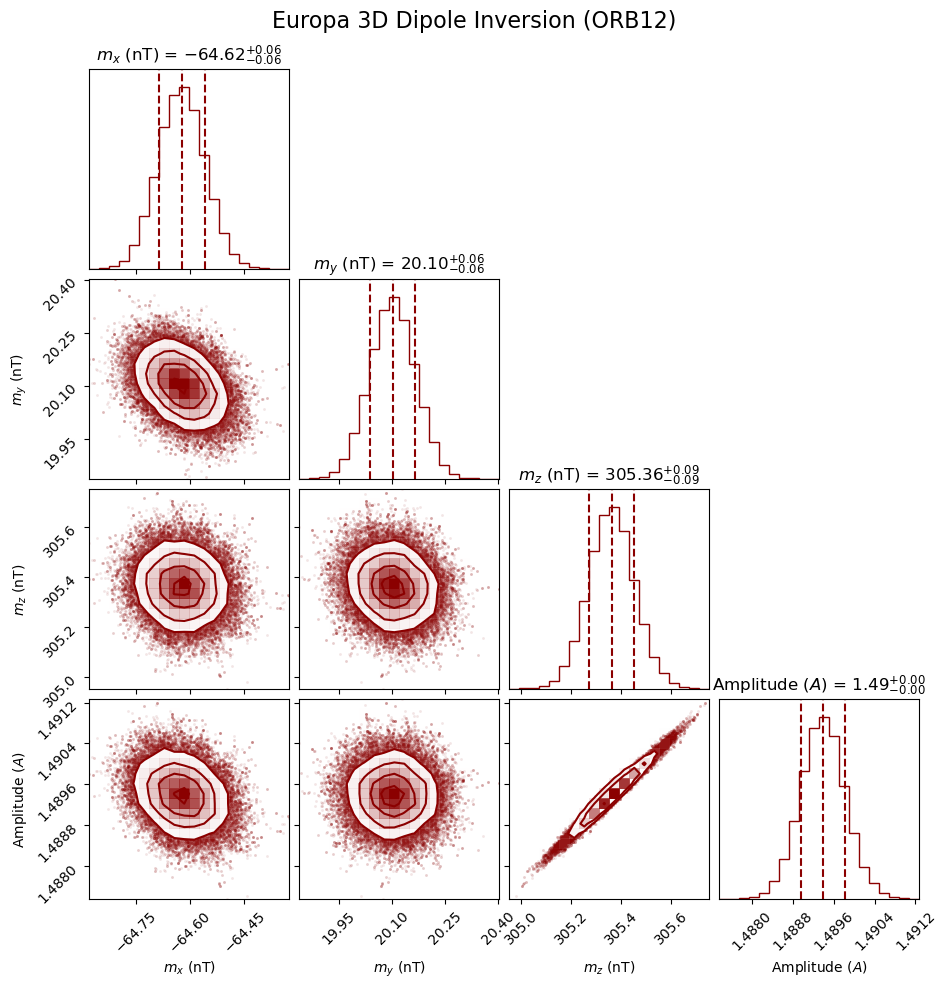

Amplitude (A) : 1.489
Phase Lag (phi) : 53.43 degrees

MCMC for ORB14


100%|██████████| 4000/4000 [00:30<00:00, 131.82it/s]


samples shape, for orbit: ORB14 : 96000
samples shapes x, y, z: 96000, 96000, 96000


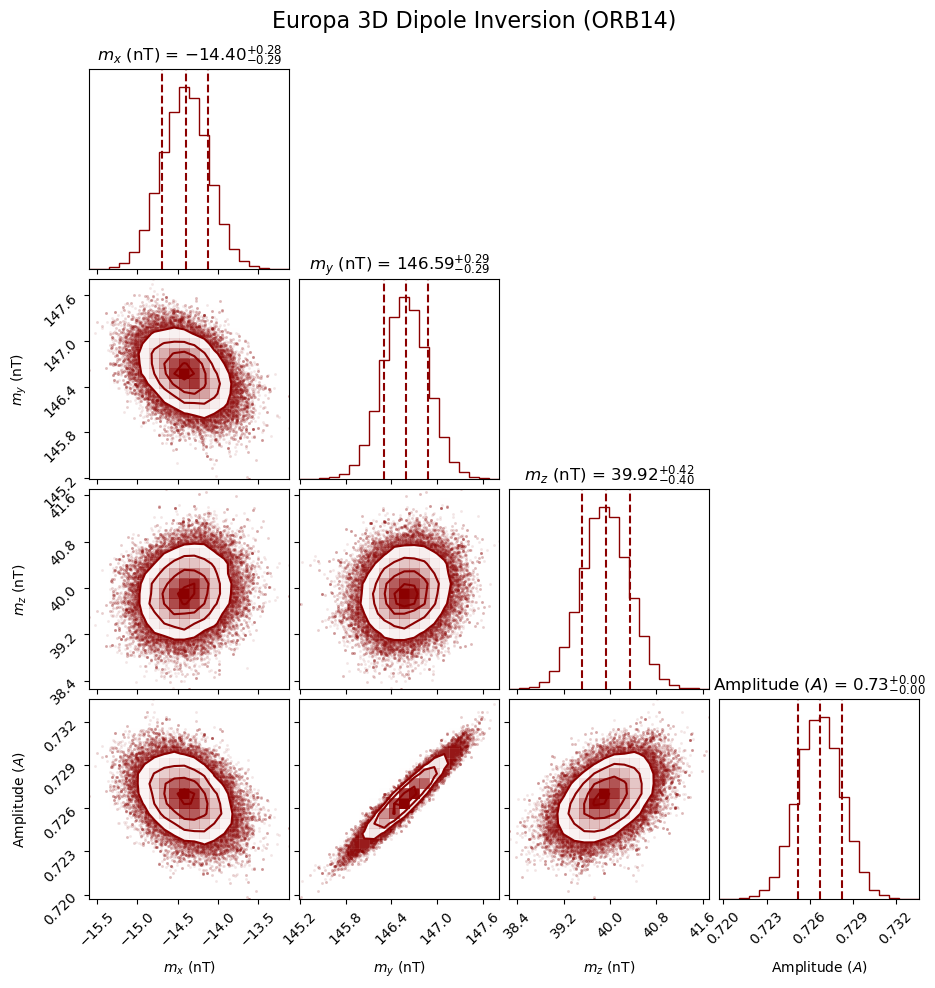

Amplitude (A) : 0.727
Phase Lag (phi) : 4.28 degrees

MCMC for ORB19


100%|██████████| 4000/4000 [00:27<00:00, 144.57it/s]


samples shape, for orbit: ORB19 : 96000
samples shapes x, y, z: 96000, 96000, 96000


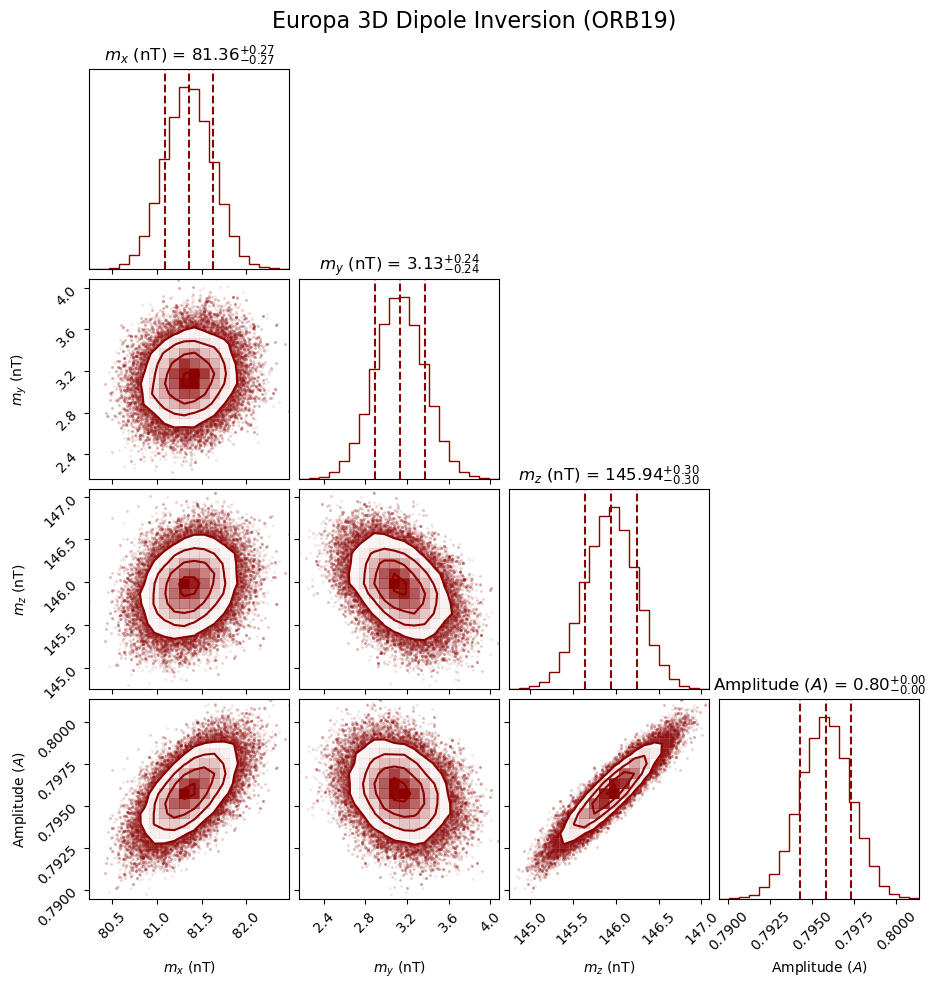

Amplitude (A) : 0.796
Phase Lag (phi) : 42.78 degrees

MCMC for ORB26


100%|██████████| 4000/4000 [00:33<00:00, 120.57it/s]


samples shape, for orbit: ORB26 : 96000
samples shapes x, y, z: 96000, 96000, 96000


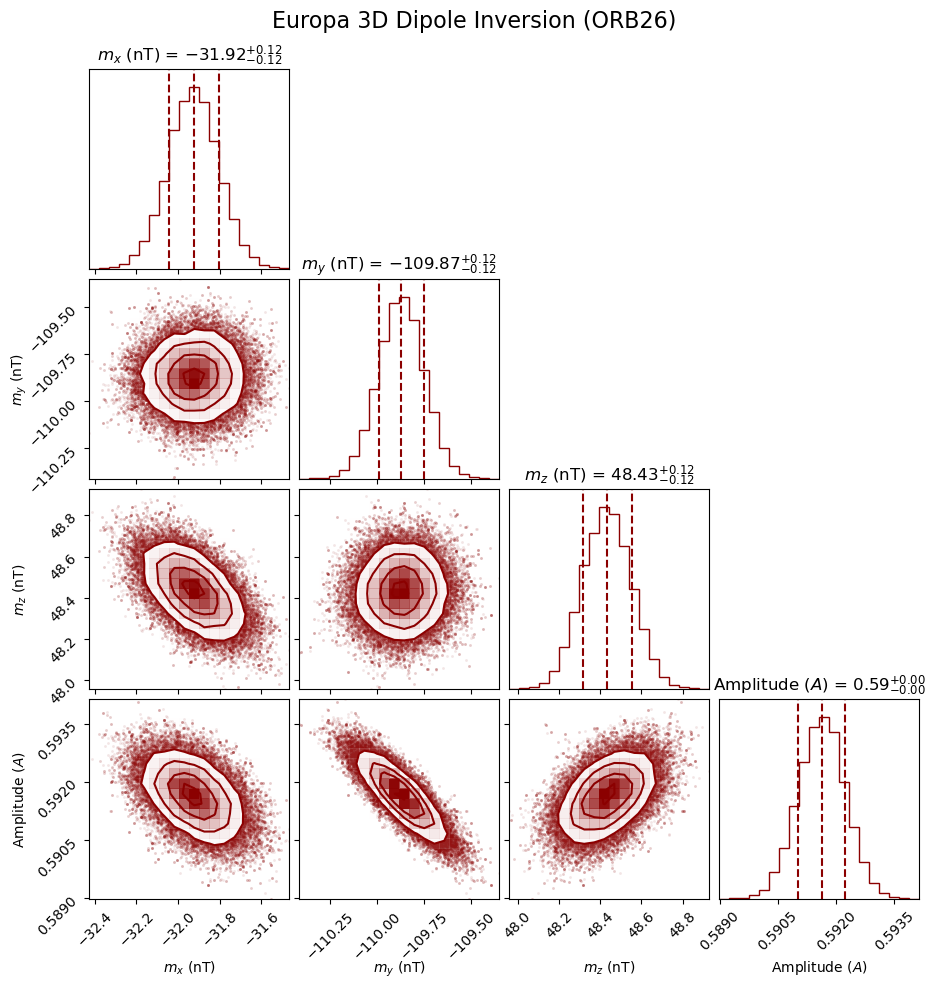

Amplitude (A) : 0.592
Phase Lag (phi) : 8.89 degrees


In [25]:
orbits = ["ORB04", 'ORB12', 'ORB14', 'ORB19', 'ORB26']

for orbit in orbits:
    print(f"\nMCMC for {orbit}")

    df = pd.read_csv(f"{orbit}_INDUCTION_READY.csv")

    X = df['X'].values
    Y = df['Y'].values
    Z = df['Z'].values

    # standarize
    if np.max(np.abs(X)) > 100:
        X = X / 1560.8
        Y = Y / 1560.8
        Z = Z / 1560.8

    BX_ind = df['BX_INDUCED'].values
    BY_ind = df['BY_INDUCED'].values
    BZ_ind = df['BZ_INDUCED'].values

    BX_pri = df['BX'].values -BX_ind
    BY_pri = df['BY'].values -BY_ind
    BZ_pri = df['BZ'].values -BZ_ind


    nwalkers = 32
    ndim = 3
    # initialize with small random spread around 0 nT
    initial_pos = [0.0, 0.0, 0.0] + 10.0 * np.random.randn(nwalkers, ndim)

    sampler = emcee.EnsembleSampler(nwalkers, ndim, log_probability,
                                    args=(X, Y, Z, BX_ind, BY_ind, BZ_ind))
    sampler.run_mcmc(initial_pos, 4000, progress=True)

    samples = sampler.get_chain(discard=1000, flat=True)


    print(f"samples shape, for orbit: {orbit} : {len(samples)}")
    print(f"samples shapes x, y, z: {len(samples[:,0])}, {len(samples[:,1])}, {len(samples[:,2])}")
    # 96_000

    B_excitation_NT = 210.0 # Nominal excitation amplitude #######################################################

    B_surf_samples = np.sqrt(samples[:, 0]**2 + samples[:, 1]**2 + samples[:, 2]**2)
    A_samples = B_surf_samples / B_excitation_NT

    plot_samples = np.column_stack((samples, A_samples))
    labels = ["$m_x$ (nT)", "$m_y$ (nT)", "$m_z$ (nT)", "Amplitude ($A$)"]

    fig = corner.corner(
        plot_samples,
        labels=labels,
        quantiles=[0.16, 0.5, 0.84],
        show_titles=True,
        title_kwargs={"fontsize": 12},
        color="darkred"
    )
    plt.suptitle(f"Europa 3D Dipole Inversion ({orbit})", y=1.02, fontsize=16)
    plt.savefig(f"Dipole_Inversion_{orbit}.png")
    plt.show()

    mx_median = np.median(samples[:, 0])
    my_median = np.median(samples[:, 1])
    A_final = np.median(A_samples)

    distances = np.sqrt(X**2 + Y**2 + Z**2)
    idx_ca = np.argmin(distances)

    bx_pri_ca = BX_pri[idx_ca]
    by_pri_ca = BY_pri[idx_ca]

    theta_pri_rad = np.arctan2(by_pri_ca, bx_pri_ca)
    theta_pri_deg = np.degrees(theta_pri_rad)

    theta_ind_rad = np.arctan2(my_median, mx_median)
    theta_ind_deg = np.degrees(theta_ind_rad)

    phase_lag_raw = (theta_pri_deg - theta_ind_deg + 180) % 360

    if phase_lag_raw > 180:
        phase_lag_final = 360 - phase_lag_raw
    elif phase_lag_raw > 90:
        phase_lag_final = 180 - phase_lag_raw
    else:
        phase_lag_final = phase_lag_raw

    print(f"Amplitude (A) : {A_final:.3f}")
    print(f"Phase Lag (phi) : {phase_lag_final:.2f} degrees")


ORB04 (A = 0.528)


100%|██████████| 5000/5000 [00:01<00:00, 2738.96it/s]


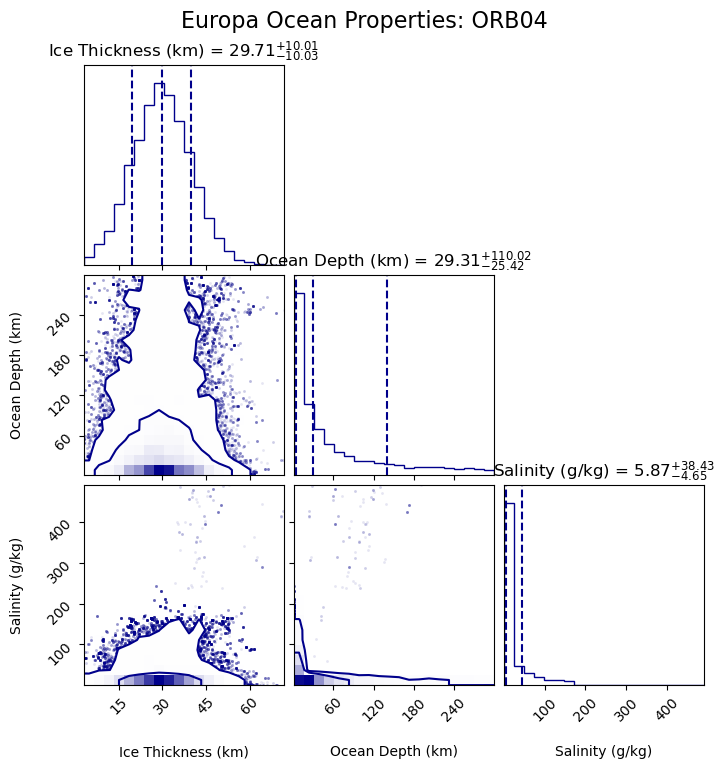


ORB12 (A = 1.603)


100%|██████████| 5000/5000 [00:01<00:00, 2637.50it/s]


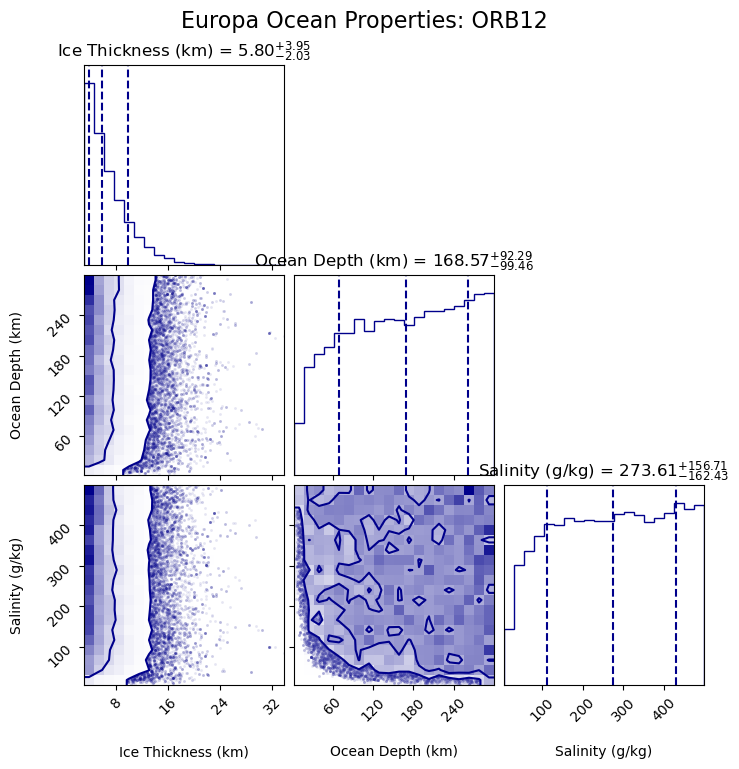


ORB14 (A = 0.727)


100%|██████████| 5000/5000 [00:01<00:00, 2720.35it/s]


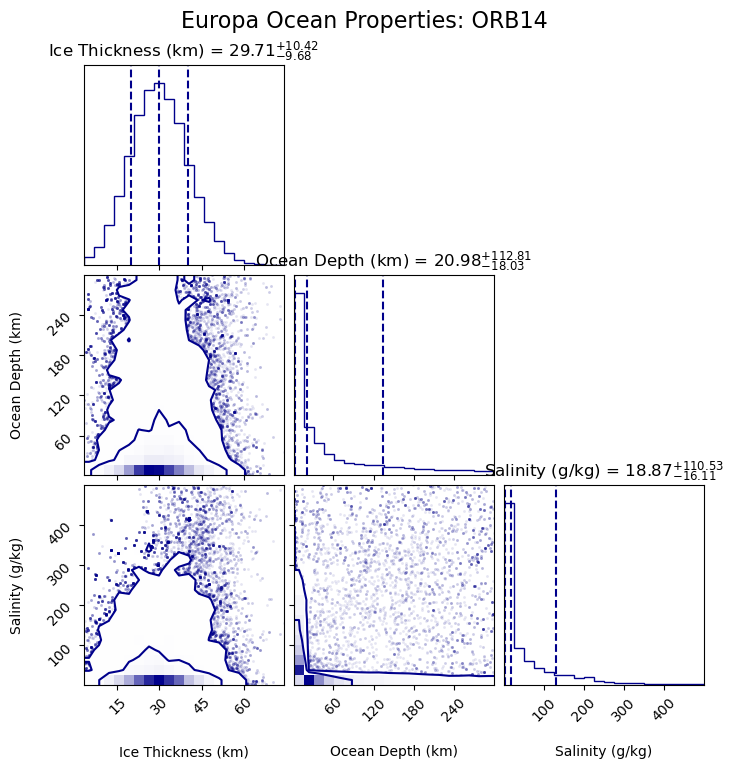


ORB19 (A = 0.724)


100%|██████████| 5000/5000 [00:01<00:00, 2744.65it/s]


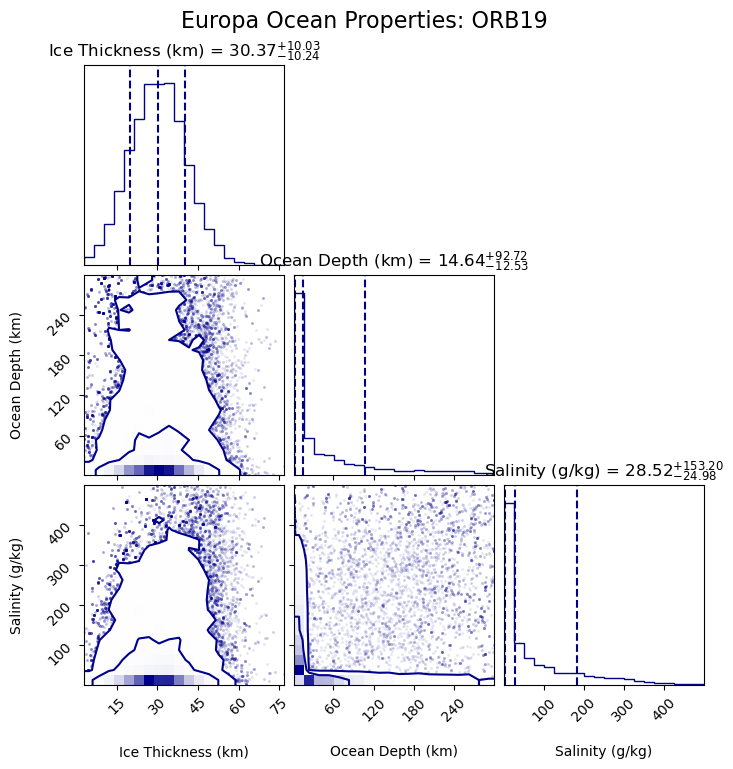


ORB26 (A = 0.592)


100%|██████████| 5000/5000 [00:01<00:00, 2725.70it/s]


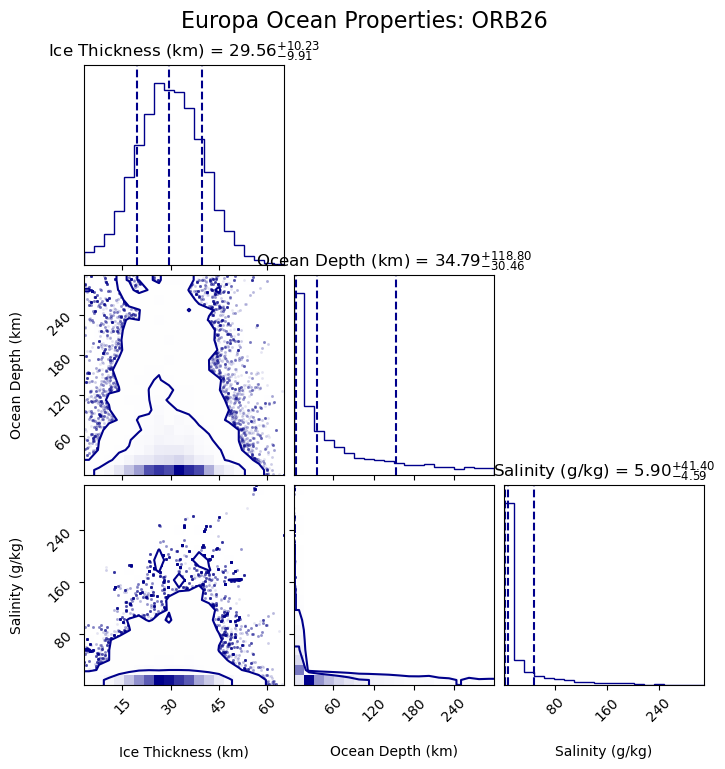

In [26]:
import numpy as np
import emcee
import corner
import matplotlib.pyplot as plt
import os

R_EUROPA_KM = 1560.8
MU_0 = 4 * np.pi * 1e-7
T_SYNODIC = 11.1 * 3600
OMEGA = 2 * np.pi / T_SYNODIC

JUNO_ICE_THICKNESS = 29.0 # km
JUNO_ICE_ERR = 10.0       # km
A_err = 0.05 #0.05

orbit_amplitudes_lags = {
    "ORB04": [0.528, 19.34 ],
    "ORB12": [1.603, 49.75],
    "ORB14": [0.727, 4.28],
    "ORB19": [0.724, 37.28],
    "ORB26": [0.592, 8.89],
    # "synthetic": [0.85, 5.0]
}

# Phi_obs_deg = phase_lag_final # Extracted phase lag in degrees
Phi_err = 5.0   # 15.0  # Uncertainty in phase lag

def forward_model(h_ice, d_ocean, sigma):
    R_c = (R_EUROPA_KM - h_ice) * 1000.0
    S = sigma * (d_ocean * 1000.0)
    tau = (MU_0 * S * R_c) / 3.0
    omega_tau = OMEGA * tau
    A_shell = omega_tau / np.sqrt(1.0 + omega_tau**2)
    A_model = A_shell * ((R_EUROPA_KM - h_ice) / R_EUROPA_KM)**3

    phi_model_rad = np.arctan(1.0 / omega_tau)
    phi_model_deg = np.degrees(phi_model_rad)
    return A_model, phi_model_deg

def log_prior(theta):
    h_ice, d_ocean, sigma = theta
    if not (3.0 < h_ice < 100.0): return -np.inf
    if not (1.0 < d_ocean < 300.0): return -np.inf
    if not (0.001 < sigma < 20.0): return -np.inf
    lp_ice = -0.5 * ((h_ice - JUNO_ICE_THICKNESS) / JUNO_ICE_ERR)**2
    return lp_ice

os.makedirs("ocean_posteriors", exist_ok=True)

for orbit, Amp_lag in orbit_amplitudes_lags.items():
    print(f"\n{orbit} (A = {Amp_lag[0]})")

    # likelihood that changes in relataion to using the current orbit's A_obs
    def log_likelihood(theta):
        h_ice, d_ocean, sigma = theta
        A_model, phi_model_deg = forward_model(h_ice, d_ocean, sigma)

        ll_A = -0.5 * ((A_model - Amp_lag[0]) / A_err)**2
        # ll_phi = -0.5 * ((phi_model_deg - Amp_lag[1]) / Phi_err)**2
        ll_phi = 0
        return ll_A + ll_phi
        # return -0.5 * ((A_model - A_obs) / A_err)**2

    def log_probability(theta):
        lp = log_prior(theta)
        if not np.isfinite(lp):
            return -np.inf
        return lp + log_likelihood(theta)

    # Initialize Walkers
    nwalkers = 32
    ndim = 3
    # Drop walkers directly onto the degeneracy curve
    # pos = [29.0, 100.0, 0.067] + 1e-4 * np.random.randn(nwalkers, ndim) ##########
    pos = [29.0, 100.0, 0.5] + 1e-4 * np.random.randn(nwalkers, ndim)


    # Run MCMC
    sampler = emcee.EnsembleSampler(nwalkers, ndim, log_probability)
    sampler.run_mcmc(pos, 5000, progress=True)

    # Post-Processing
    samples = sampler.get_chain(discard=1000, flat=True)
    salinity_samples = samples[:, 2] * 25.0 # before * 10.0 1 S/m -> 25 g/kg
    samples_plot = np.column_stack((samples[:, 0], samples[:, 1], salinity_samples))
    labels = ["Ice Thickness (km)", "Ocean Depth (km)", "Salinity (g/kg)"]

    # Generate and Save Corner Plot
    fig = corner.corner(
        samples_plot,
        labels=labels,
        quantiles=[0.16, 0.5, 0.84],
        levels = [0.68, 0.95],
        show_titles=True,
        title_kwargs={"fontsize": 12},
        color="darkblue"
    )
    plt.suptitle(f"Europa Ocean Properties: {orbit}", y=1.02, fontsize=16)

    # Dynamically save the figure using the orbit name
    filename = f"ocean_posteriors/thickness_depth_salinity_{orbit}.png"
    plt.savefig(filename, bbox_inches='tight')
    plt.show()
    plt.close(fig) # Free memory before next loop iteration

Running MCMC for ORB04 (A = 0.528)...
Running MCMC for ORB14 (A = 0.727)...
Running MCMC for ORB26 (A = 0.592)...


/home/damian/miniconda3/lib/python3.13/site-packages/matplotlib/scale.py:270: RuntimeWarning: overflow encountered in power
  return np.power(self.base, values)


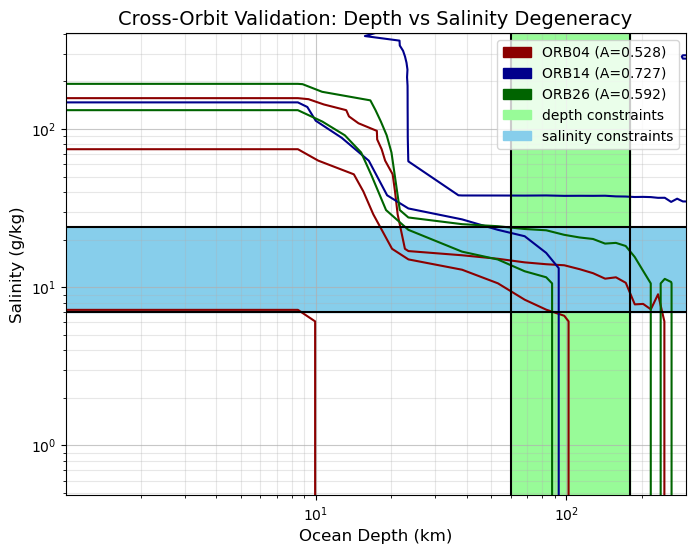

In [27]:
import numpy as np
import emcee
import corner
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# --- CONSTANTS & JUNO PRIOR ---
R_EUROPA_KM = 1560.8
MU_0 = 4 * np.pi * 1e-7
T_SYNODIC = 11.1 * 3600
OMEGA = 2 * np.pi / T_SYNODIC

JUNO_ICE_THICKNESS = 29.0
JUNO_ICE_ERR = 10.0
A_err = 0.05

orbit_amplitudes = {
    "ORB04": {"A": 0.528, "color": "darkred"},
    "ORB14": {"A": 0.727, "color": "darkblue"},
    "ORB26": {"A": 0.592, "color": "darkgreen"}
    # "synthetic": {"A": 0.85, "color": "seagreen"}
}

def forward_model(h_ice, d_ocean, sigma):
    R_c = (R_EUROPA_KM - h_ice) * 1000.0
    S = sigma * (d_ocean * 1000.0)
    tau = (MU_0 * S * R_c) / 3.0
    omega_tau = OMEGA * tau
    A_shell = omega_tau / np.sqrt(1.0 + omega_tau**2)
    return A_shell * ((R_EUROPA_KM - h_ice) / R_EUROPA_KM)**3

def log_prior(theta):
    h_ice, d_ocean, sigma = theta
    if not (3.0 < h_ice < 100.0): return -np.inf
    if not (1.0 < d_ocean < 300.0): return -np.inf
    if not (0.001 < sigma < 20.0): return -np.inf
    return -0.5 * ((h_ice - JUNO_ICE_THICKNESS) / JUNO_ICE_ERR)**2

fig, ax = plt.subplots(figsize=(8, 6))
legend_handles = []

for orbit, params in orbit_amplitudes.items():
    A_obs = params["A"]
    orbit_color = params["color"]

    print(f"Running MCMC for {orbit} (A = {A_obs})...")

    def log_likelihood(theta):
        h_ice, d_ocean, sigma = theta
        A_model = forward_model(h_ice, d_ocean, sigma)
        return -0.5 * ((A_model - A_obs) / A_err)**2

    def log_probability(theta):
        lp = log_prior(theta)
        if not np.isfinite(lp):
            return -np.inf
        return lp + log_likelihood(theta)

    # Initialize and run walkers
    nwalkers = 32
    ndim = 3
    # pos = [29.0, 100.0, 0.067] + 1e-4 * np.random.randn(nwalkers, ndim) ########################
    pos = [29.0, 100.0, 0.5] + 1e-4 * np.random.randn(nwalkers, ndim)


    sampler = emcee.EnsembleSampler(nwalkers, ndim, log_probability)
    sampler.run_mcmc(pos, 4000, progress=False) # Progress disabled for cleaner console

    # Extract depth and salinity samples
    samples = sampler.get_chain(discard=1000, flat=True)
    depth_samples = samples[:, 1]
    salinity_samples = samples[:, 2] * 25.0 # Convert S/m to g/kg  # * 10 before
    # for MgSO4 1 S/m -> 25 g/kg

    # Plot only the 2D contours on the shared axis using corner's hist2d
    corner.hist2d(depth_samples, salinity_samples, ax=ax, color=orbit_color,
                  plot_datapoints=False, plot_density=False, levels=[0.68, 0.95])

    # Add to legend
    legend_handles.append(mpatches.Patch(color=orbit_color, label=f"{orbit} (A={A_obs})"))


ax.axvspan(60, 180, color='palegreen')
legend_handles.append(mpatches.Patch(color='palegreen', label=f"depth constraints"))
ax.axvline(60, 0, 90, color='black')
ax.axvline(180, 0, 90, color='black')


ax.axhline(7, 0, 200, color='black')
ax.set_yscale("log")
ax.set_xscale("log")
ax.axhspan(7, 24, label="salinity constraints", color='skyblue')
legend_handles.append(mpatches.Patch(color='skyblue', label=f"salinity constraints"))
ax.axhline(24, 0, 200, color='black')


ax.set_xlabel("Ocean Depth (km)", fontsize=12)
ax.set_ylabel("Salinity (g/kg)", fontsize=12)
ax.set_title("Cross-Orbit Validation: Depth vs Salinity Degeneracy", fontsize=14)
ax.legend(handles=legend_handles, loc="upper right")
ax.minorticks_on()
ax.grid(which="major", alpha=0.7)
ax.grid(which='minor', alpha=0.3)

# plt.ylim(5, 30)
# plt.xlim(50, 200)
# plt.ylim(7, 24)
# plt.xlim(60, 180)


# ax.grid(alpha=0.3)

plt.savefig("Cross_Orbit_Validation.png", dpi=300, bbox_inches='tight')
plt.show()

Running MCMC for ORB04 (A = 0.528)...
Running MCMC for ORB14 (A = 0.727)...
Running MCMC for ORB26 (A = 0.592)...


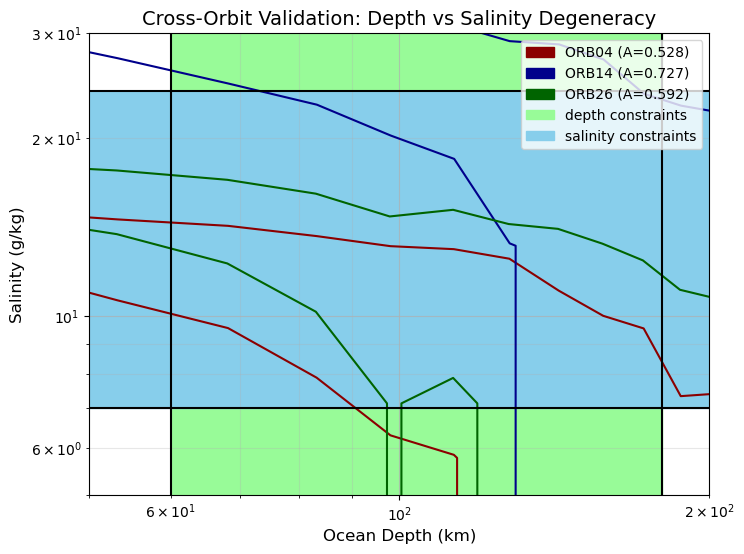

In [28]:
import numpy as np
import emcee
import corner
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# --- CONSTANTS & JUNO PRIOR ---
R_EUROPA_KM = 1560.8
MU_0 = 4 * np.pi * 1e-7
T_SYNODIC = 11.1 * 3600
OMEGA = 2 * np.pi / T_SYNODIC

JUNO_ICE_THICKNESS = 29.0
JUNO_ICE_ERR = 10.0
A_err = 0.05

orbit_amplitudes = {
    "ORB04": {"A": 0.528, "color": "darkred"},
    "ORB14": {"A": 0.727, "color": "darkblue"},
    "ORB26": {"A": 0.592, "color": "darkgreen"}
    # "synthetic": {"A": 0.85, "color": "seagreen"}
}

def forward_model(h_ice, d_ocean, sigma):
    R_c = (R_EUROPA_KM - h_ice) * 1000.0
    S = sigma * (d_ocean * 1000.0)
    tau = (MU_0 * S * R_c) / 3.0
    omega_tau = OMEGA * tau
    A_shell = omega_tau / np.sqrt(1.0 + omega_tau**2)
    return A_shell * ((R_EUROPA_KM - h_ice) / R_EUROPA_KM)**3

def log_prior(theta):
    h_ice, d_ocean, sigma = theta
    if not (3.0 < h_ice < 100.0): return -np.inf
    if not (1.0 < d_ocean < 300.0): return -np.inf
    if not (0.001 < sigma < 20.0): return -np.inf
    return -0.5 * ((h_ice - JUNO_ICE_THICKNESS) / JUNO_ICE_ERR)**2

fig, ax = plt.subplots(figsize=(8, 6))
legend_handles = []

for orbit, params in orbit_amplitudes.items():
    A_obs = params["A"]
    orbit_color = params["color"]

    print(f"Running MCMC for {orbit} (A = {A_obs})...")

    def log_likelihood(theta):
        h_ice, d_ocean, sigma = theta
        A_model = forward_model(h_ice, d_ocean, sigma)
        return -0.5 * ((A_model - A_obs) / A_err)**2

    def log_probability(theta):
        lp = log_prior(theta)
        if not np.isfinite(lp):
            return -np.inf
        return lp + log_likelihood(theta)

    # Initialize and run walkers
    nwalkers = 32
    ndim = 3
    # pos = [29.0, 100.0, 0.067] + 1e-4 * np.random.randn(nwalkers, ndim) ########################
    pos = [29.0, 100.0, 0.5] + 1e-4 * np.random.randn(nwalkers, ndim)


    sampler = emcee.EnsembleSampler(nwalkers, ndim, log_probability)
    sampler.run_mcmc(pos, 4000, progress=False) # Progress disabled for cleaner console

    # Extract depth and salinity samples
    samples = sampler.get_chain(discard=1000, flat=True)
    depth_samples = samples[:, 1]
    salinity_samples = samples[:, 2] * 25.0 # Convert S/m to g/kg  # * 10 before
    # for MgSO4 1 S/m -> 25 g/kg

    # Plot only the 2D contours on the shared axis using corner's hist2d
    corner.hist2d(depth_samples, salinity_samples, ax=ax, color=orbit_color,
                  plot_datapoints=False, plot_density=False, levels=[0.68, 0.95])

    # Add to legend
    legend_handles.append(mpatches.Patch(color=orbit_color, label=f"{orbit} (A={A_obs})"))


ax.axvspan(60, 180, color='palegreen')
legend_handles.append(mpatches.Patch(color='palegreen', label=f"depth constraints"))
ax.axvline(60, 0, 90, color='black')
ax.axvline(180, 0, 90, color='black')

ax.set_yscale("log")
ax.set_xscale("log")


ax.axhline(7, 0, 200, color='black')
ax.axhspan(7, 24, label="salinity constraints", color='skyblue')
legend_handles.append(mpatches.Patch(color='skyblue', label=f"salinity constraints"))
ax.axhline(24, 0, 200, color='black')


ax.set_xlabel("Ocean Depth (km)", fontsize=12)
ax.set_ylabel("Salinity (g/kg)", fontsize=12)
ax.set_title("Cross-Orbit Validation: Depth vs Salinity Degeneracy", fontsize=14)
ax.legend(handles=legend_handles, loc="upper right")
ax.minorticks_on()
ax.grid(which="major", alpha=0.7)
ax.grid(which='minor', alpha=0.3)

plt.ylim(5, 30)
plt.xlim(50, 200)
# plt.ylim(7, 24)
# plt.xlim(60, 180)


# ax.grid(alpha=0.3)

plt.savefig("Cross_Orbit_Validation.png", dpi=300, bbox_inches='tight')
plt.show()

In [29]:
# do scatter instead of plot
# lines in between are guide to the eye

# stoichiometry

0 8.0
1 3.0
2 0.0
3 -1.0
4 0.0
5 3.0


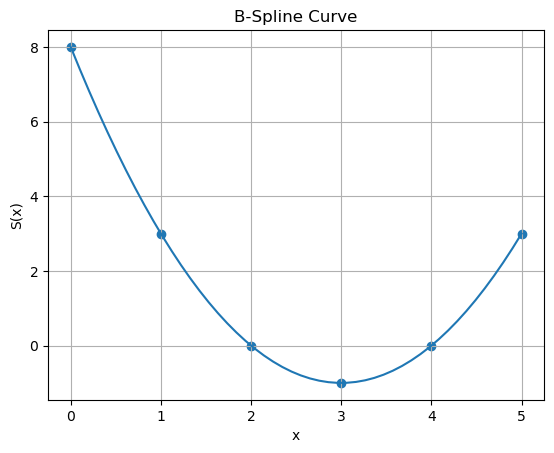

In [30]:
import numpy as np
from scipy.interpolate import BSpline
import matplotlib.pyplot as plt

# Define knot vector, coefficients, and degree
t = [0, 1, 2, 3, 4, 5]
c = [1, -1, -1]
k = 2

# Create a BSpline object
spl = BSpline(t, c, k)

# Evaluate the spline at multiple points
x = np.linspace(0, 5.0, 50)
y = spl(x)

y_spl = [spl(x) for x in t]
for point in t:
  print(point, spl(point))

plt.plot(x, y)
plt.scatter(t, y_spl)
plt.title('B-Spline Curve')
plt.xlabel('x')
plt.ylabel('S(x)')
plt.grid(True)
plt.show()